
SESSION 5: K-NEAREST NEIGHBOURS (K-NN)
Using Colab cache for faster access to the 'iris' dataset.
Loaded from Kaggle: /kaggle/input/iris/Iris.csv
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa


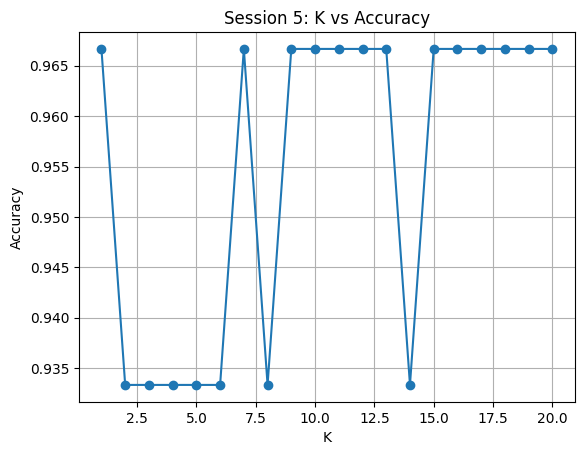

[Session 5] Best K = 1
[Session 5] Accuracy: 0.9666666666666667
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.91      1.00      0.95        10
 Iris-virginica       1.00      0.90      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



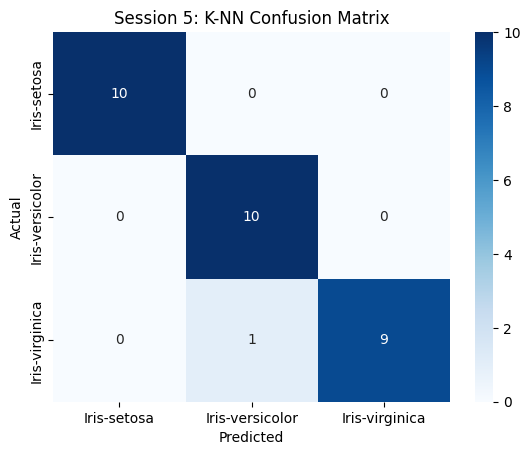


SESSION 7: LOGISTIC REGRESSION (LR) ALGORITHM


100%|██████████| 48.6k/48.6k [00:00<00:00, 1.48MB/s]

Extracting files...
Loaded from Kaggle: /root/.cache/kagglehub/datasets/yasserh/breast-cancer-dataset/versions/1/breast-cancer.csv
Shape: (569, 31)
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38           122.8     1001.0   
1          1        20.57         17.77           132.9     1326.0   
2          1        19.69         21.25           130.0     1203.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0         0.2419  ...         25.38          17.33            184.6   
1         0.1812  ...         24.99          23.41            158.8   
2         0.2069  ...         23.57          25.5

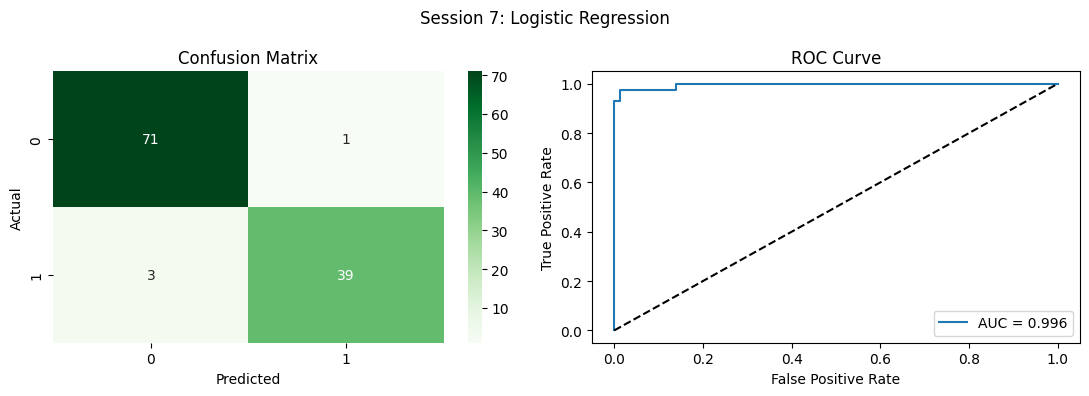


SESSION 8: LINEAR REGRESSION (LR) ALGORITHM


100%|██████████| 457/457 [00:00<00:00, 266kB/s]

Extracting files...
Loaded from Kaggle: /root/.cache/kagglehub/datasets/abhishek14398/salary-dataset-simple-linear-regression/versions/1/Salary_dataset.csv
       Unnamed: 0  YearsExperience         Salary
count   30.000000        30.000000      30.000000
mean    14.500000         5.413333   76004.000000
std      8.803408         2.837888   27414.429785
min      0.000000         1.200000   37732.000000
25%      7.250000         3.300000   56721.750000
50%     14.500000         4.800000   65238.000000
75%     21.750000         7.800000  100545.750000
max     29.000000        10.600000  122392.000000

[Session 8] Intercept: 24380.201479473704
[Session 8] Slope    : 9423.815323030976
[Session 8] MAE : 6286.453830757745
[Session 8] MSE : 49830096.855908394
[Session 8] RMSE: 7059.04362190151
[Session 8] R2  : 0.9024461774180497


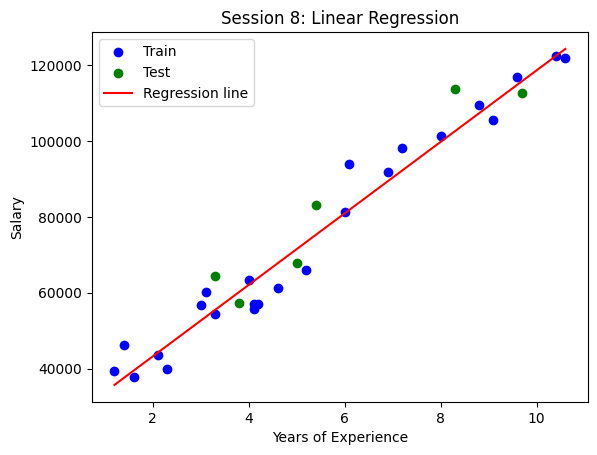

[Session 8] Salary for 5 years: 71499.2780946286

SESSION 9: COMPARE LINEAR AND POLYNOMIAL REGRESSION


100%|██████████| 333/333 [00:00<00:00, 767kB/s]

Extracting files...
Loaded from Kaggle: /root/.cache/kagglehub/datasets/akram24/position-salaries/versions/1/Position_Salaries.csv
            Position  Level   Salary
0   Business Analyst      1    45000
1  Junior Consultant      2    50000
2  Senior Consultant      3    60000
3            Manager      4    80000
4    Country Manager      5   110000
5     Region Manager      6   150000
6            Partner      7   200000
7     Senior Partner      8   300000
8            C-level      9   500000
9                CEO     10  1000000

[Session 9] Model comparison:
                Model     R2        RMSE
0      Linear (deg 1)  0.669  163388.735
1  Polynomial (deg 2)  0.916   82212.124
2  Polynomial (deg 3)  0.981   38931.504
3  Polynomial (deg 4)  0.997   14503.235


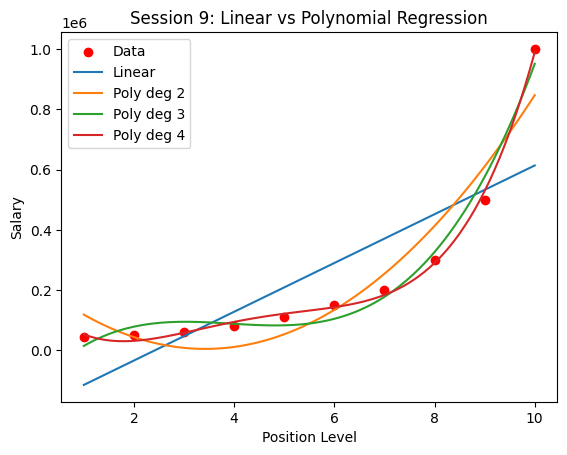

[Session 9] Level 6.5 -> Linear    : 330378.78787878784
[Session 9] Level 6.5 -> Poly deg 4: 158862.45265155006


In [7]:
!pip -q install kagglehub
import glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, mean_absolute_error,
                             mean_squared_error, r2_score)

def try_kaggle(handle, filename=None):
    """Try Kaggle; return DataFrame, or None if it fails (no crash)."""
    try:
        import kagglehub
        path = kagglehub.dataset_download(handle)
        files = glob.glob(path + '/**/*.csv', recursive=True)
        if filename:
            files = [f for f in files if f.lower().endswith(filename.lower())] or files
        print('Loaded from Kaggle:', files[0])
        return pd.read_csv(files[0])
    except Exception as e:
        print(f'Kaggle not available ({str(e)[:60]}...) -> using built-in data instead')
        return None

def banner(t):
    print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)


# ======================================================================
# SESSION 5: K-NEAREST NEIGHBOURS (K-NN)
# ======================================================================
banner('SESSION 5: K-NEAREST NEIGHBOURS (K-NN)')

df5 = try_kaggle('uciml/iris', 'Iris.csv')
if df5 is None or 'Species' not in df5.columns:
    d = load_iris(as_frame=True)
    df5 = d.frame.copy()
    df5['Species'] = d.target_names[d.target]
    df5 = df5.drop(columns='target')
df5 = df5.drop(columns=[c for c in df5.columns if c.lower() == 'id'])
print(df5.head())

X5, y5 = df5.drop(columns='Species'), df5['Species']
X5_tr, X5_te, y5_tr, y5_te = train_test_split(X5, y5, test_size=0.2, random_state=42, stratify=y5)
sc5 = StandardScaler()
X5_tr_s, X5_te_s = sc5.fit_transform(X5_tr), sc5.transform(X5_te)

ks = range(1, 21)
accs = [accuracy_score(y5_te, KNeighborsClassifier(n_neighbors=k).fit(X5_tr_s, y5_tr).predict(X5_te_s)) for k in ks]
best_k = ks[int(np.argmax(accs))]
plt.plot(ks, accs, marker='o'); plt.xlabel('K'); plt.ylabel('Accuracy')
plt.title('Session 5: K vs Accuracy'); plt.grid(True); plt.show()
print('[Session 5] Best K =', best_k)

knn = KNeighborsClassifier(n_neighbors=best_k).fit(X5_tr_s, y5_tr)
p5 = knn.predict(X5_te_s)
print('[Session 5] Accuracy:', accuracy_score(y5_te, p5))
print(classification_report(y5_te, p5))
sns.heatmap(confusion_matrix(y5_te, p5), annot=True, fmt='d', cmap='Blues',
            xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.title('Session 5: K-NN Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()


# ======================================================================
# SESSION 7: LOGISTIC REGRESSION (Breast Cancer dataset)
# ======================================================================
banner('SESSION 7: LOGISTIC REGRESSION (LR) ALGORITHM')

df7 = try_kaggle('yasserh/breast-cancer-dataset')
if df7 is not None and 'diagnosis' in df7.columns:
    df7 = df7.drop(columns=[c for c in df7.columns if c.lower() == 'id'])
    df7['diagnosis'] = (df7['diagnosis'] == 'M').astype(int)   # M=1, B=0
else:
    d = load_breast_cancer(as_frame=True)
    df7 = d.frame.rename(columns={'target': 'diagnosis'})
    df7['diagnosis'] = 1 - df7['diagnosis']                    # make malignant = 1
print('Shape:', df7.shape)
print(df7.head(3))

X7, y7 = df7.drop(columns='diagnosis'), df7['diagnosis']
X7_tr, X7_te, y7_tr, y7_te = train_test_split(X7, y7, test_size=0.2, random_state=42, stratify=y7)
sc7 = StandardScaler()
X7_tr_s, X7_te_s = sc7.fit_transform(X7_tr), sc7.transform(X7_te)

lr = LogisticRegression(max_iter=1000).fit(X7_tr_s, y7_tr)
p7 = lr.predict(X7_te_s)
prob7 = lr.predict_proba(X7_te_s)[:, 1]
print('\n[Session 7] Accuracy:', accuracy_score(y7_te, p7))
print('[Session 7] ROC-AUC :', roc_auc_score(y7_te, prob7))
print(classification_report(y7_te, p7))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Session 7: Logistic Regression')
sns.heatmap(confusion_matrix(y7_te, p7), annot=True, fmt='d', cmap='Greens', ax=ax[0])
ax[0].set_title('Confusion Matrix'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y7_te, prob7)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y7_te, prob7):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_title('ROC Curve'); ax[1].set_xlabel('False Positive Rate'); ax[1].set_ylabel('True Positive Rate'); ax[1].legend()
plt.tight_layout(); plt.show()


# ======================================================================
# SESSION 8: LINEAR REGRESSION (Salary dataset)
# ======================================================================
banner('SESSION 8: LINEAR REGRESSION (LR) ALGORITHM')

df8 = try_kaggle('abhishek14398/salary-dataset-simple-linear-regression')
if df8 is None or not {'YearsExperience', 'Salary'}.issubset(df8.columns):
    df8 = pd.DataFrame({
        'YearsExperience': [1.1,1.3,1.5,2.0,2.2,2.9,3.0,3.2,3.2,3.7,3.9,4.0,4.0,4.1,4.5,
                            4.9,5.1,5.3,5.9,6.0,6.8,7.1,7.9,8.2,8.7,9.0,9.5,9.6,10.3,10.5],
        'Salary': [39343,46205,37731,43525,39891,56642,60150,54445,64445,57189,63218,55794,
                   56957,57081,61111,67938,66029,83088,81363,93940,91738,98273,101302,113812,
                   109431,105582,116969,112635,122391,121872]})
print(df8.describe())

X8, y8 = df8[['YearsExperience']], df8['Salary']
X8_tr, X8_te, y8_tr, y8_te = train_test_split(X8, y8, test_size=0.2, random_state=42)
lin8 = LinearRegression().fit(X8_tr, y8_tr)
p8 = lin8.predict(X8_te)
print('\n[Session 8] Intercept:', lin8.intercept_)
print('[Session 8] Slope    :', lin8.coef_[0])
print('[Session 8] MAE :', mean_absolute_error(y8_te, p8))
print('[Session 8] MSE :', mean_squared_error(y8_te, p8))
print('[Session 8] RMSE:', np.sqrt(mean_squared_error(y8_te, p8)))
print('[Session 8] R2  :', r2_score(y8_te, p8))

plt.scatter(X8_tr, y8_tr, color='blue', label='Train')
plt.scatter(X8_te, y8_te, color='green', label='Test')
plt.plot(X8, lin8.predict(X8), color='red', label='Regression line')
plt.xlabel('Years of Experience'); plt.ylabel('Salary')
plt.title('Session 8: Linear Regression'); plt.legend(); plt.show()
print('[Session 8] Salary for 5 years:', lin8.predict(pd.DataFrame({'YearsExperience': [5]}))[0])


# ======================================================================
# SESSION 9: LINEAR vs POLYNOMIAL REGRESSION (Position Salaries)
# ======================================================================
banner('SESSION 9: COMPARE LINEAR AND POLYNOMIAL REGRESSION')

df9 = try_kaggle('akram24/position-salaries', 'Position_Salaries.csv')
if df9 is None or not {'Level', 'Salary'}.issubset(df9.columns):
    df9 = pd.DataFrame({
        'Position': ['Business Analyst','Junior Consultant','Senior Consultant','Manager',
                     'Country Manager','Region Manager','Partner','Senior Partner','C-level','CEO'],
        'Level': list(range(1, 11)),
        'Salary': [45000,50000,60000,80000,110000,150000,200000,300000,500000,1000000]})
print(df9)

X9, y9 = df9[['Level']].values, df9['Salary'].values
lin9 = LinearRegression().fit(X9, y9)
res9 = [('Linear (deg 1)', r2_score(y9, lin9.predict(X9)),
         np.sqrt(mean_squared_error(y9, lin9.predict(X9))))]
models9 = {}
for deg in [2, 3, 4]:
    pf = PolynomialFeatures(degree=deg)
    m = LinearRegression().fit(pf.fit_transform(X9), y9)
    models9[deg] = (pf, m)
    pr = m.predict(pf.transform(X9))
    res9.append((f'Polynomial (deg {deg})', r2_score(y9, pr), np.sqrt(mean_squared_error(y9, pr))))
print('\n[Session 9] Model comparison:')
print(pd.DataFrame(res9, columns=['Model', 'R2', 'RMSE']).round(3))

grid = np.arange(X9.min(), X9.max() + 0.1, 0.1).reshape(-1, 1)
plt.scatter(X9, y9, color='red', label='Data')
plt.plot(grid, lin9.predict(grid), label='Linear')
for deg, (pf, m) in models9.items():
    plt.plot(grid, m.predict(pf.transform(grid)), label=f'Poly deg {deg}')
plt.xlabel('Position Level'); plt.ylabel('Salary')
plt.title('Session 9: Linear vs Polynomial Regression'); plt.legend(); plt.show()

pf4, m4 = models9[4]
print('[Session 9] Level 6.5 -> Linear    :', lin9.predict([[6.5]])[0])
print('[Session 9] Level 6.5 -> Poly deg 4:', m4.predict(pf4.transform([[6.5]]))[0])